# IMDb Top 1000 Movies: Exploratory Data Analysis

**Course:** CSB314 - Exploratory Data Analysis  
**Assessment:** Minor Project 02 (CA 03)

This notebook explores the supplied `imdb_top_1000.csv` file. It checks data quality, creates useful features from the movie fields, summarizes ratings and genres, and applies the statistical methods listed in the project brief.

The file contains 1,000 movie records and fields about title, release year, certificate, runtime, genre, IMDb rating, Metascore, director, cast, votes, and gross. It is a selected top-movies snapshot, not a random sample of every movie. Conclusions describe these records only.

## 1. Problem and objectives

The aim is to understand what the supplied movie table shows about the selected films. The analysis focuses on movie ratings, runtime, release periods, genres, vote counts, Metascores, and gross values.

The work follows the assignment topics: data-quality checks, feature engineering, grouping and transformation, pivot tables and crosstabs, reshaping, join validation, descriptive statistics, distributions, sampling, correlation, and outlier assessment.

The main interpretation question is how these movie fields vary together in the supplied top-1000 list. These patterns are descriptive. The data cannot show that one feature causes another, and the selected list should not be treated as a representative sample of all films.

## 2. Dataset source and description

The supplied file is `imdb_top_1000.csv`, a common version of the IMDb Top 1000 Movies dataset published on Kaggle. A likely matching source page is [IMDb Dataset of Top 1000 Movies and TV Shows](https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows). The source page and licence should be checked against the copy used for this project because no separate licence file was supplied.

The columns include movie title, release year, certificate, runtime, genre, IMDb rating, overview, Metascore, director, four cast fields, number of votes, and gross. The title identifies each movie in this file. `Poster_Link` points to an image and is not used in the numerical analysis.

## 3. Import libraries and load data

Pandas loads, checks, groups, and reshapes the data. NumPy supports calculations and repeatable sampling. Matplotlib and Seaborn produce the charts. Keep `imdb_top_1000.csv` in the same folder as this notebook.

The source table is stored in `movies_raw`. A separate working copy is used for parsed and derived fields so the source columns are not overwritten.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")

data_path = Path("imdb_top_1000.csv")
if not data_path.exists():
    raise FileNotFoundError("Place imdb_top_1000.csv in the same folder as this notebook.")

movies_raw = pd.read_csv(data_path)
movies = movies_raw.copy()
print(f"Loaded {movies.shape[0]:,} rows and {movies.shape[1]} columns.")
display(movies.head())

Loaded 1,000 rows and 16 columns.


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,"https://m.media-amazon.com/images/M/MV5BMDFkYTc0MGEtZmNhMC00ZDIzLWFmNTEtODM1ZmRlYWMwMWFmXkEyXkFqcGdeQXVyMTMxODk2OTU@._V1_UX67_CR0,0,67,98_AL_.jpg",The Shawshank Redemption,1994,A,142 min,Drama,9.3,"Two imprisoned men bond over a number of years, finding solace and eventual redemption through acts of common decency.",80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,"https://m.media-amazon.com/images/M/MV5BM2MyNjYxNmUtYTAwNi00MTYxLWJmNWYtYzZlODY3ZTk3OTFlXkEyXkFqcGdeQXVyNzkwMjQ5NzM@._V1_UY98_CR1,0,67,98_AL_.jpg",The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch transfers control of his clandestine empire to his reluctant son.,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,"https://m.media-amazon.com/images/M/MV5BMTMxNTMwODM0NF5BMl5BanBnXkFtZTcwODAyMTk2Mw@@._V1_UX67_CR0,0,67,98_AL_.jpg",The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,"When the menace known as the Joker wreaks havoc and chaos on the people of Gotham, Batman must accept one of the greatest psychological and physical tests of his ability to fight injustice.",84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,"https://m.media-amazon.com/images/M/MV5BMWMwMGQzZTItY2JlNC00OWZiLWIyMDctNDk2ZDQ2YjRjMWQ0XkEyXkFqcGdeQXVyNzkwMjQ5NzM@._V1_UY98_CR1,0,67,98_AL_.jpg",The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,"The early life and career of Vito Corleone in 1920s New York City is portrayed, while his son, Michael, expands and tightens his grip on the family crime syndicate.",90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,"https://m.media-amazon.com/images/M/MV5BMWU4N2FjNzYtNTVkNC00NzQ0LTg0MjAtYTJlMjFhNGUxZDFmXkEyXkFqcGdeQXVyNjc1NTYyMjg@._V1_UX67_CR0,0,67,98_AL_.jpg",12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarriage of justice by forcing his colleagues to reconsider the evidence.,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


## 4. Dataset understanding and row grain

Each row is intended to represent one movie. The title is checked for uniqueness, and data types and distinct-value counts are shown to understand which columns are numeric, categorical, or descriptive text.

Some fields that look numeric are stored as text, such as release year, runtime, and gross. They are parsed in a later section. The source values are kept so that parsing failures can be identified rather than silently changed.

In [2]:
print("Shape:", movies.shape)
print("Data types:")
display(movies.dtypes.rename("data_type").to_frame())
print("Unique values per column:")
display(movies.nunique().rename("unique_values").to_frame())
print("Movie title unique:", movies["Series_Title"].is_unique)
print("Exact duplicate rows:", movies.duplicated().sum())

Shape: (1000, 16)
Data types:
Unique values per column:
Movie title unique: False
Exact duplicate rows: 0


,data_type
Poster_Link,str
Series_Title,str
Released_Year,str
Certificate,str
Runtime,str
Genre,str
IMDB_Rating,float64
Overview,str
Meta_score,float64
Director,str


,unique_values
Poster_Link,1000
Series_Title,999
Released_Year,100
Certificate,16
Runtime,140
Genre,202
IMDB_Rating,17
Overview,1000
Meta_score,63
Director,548


The table has one row per movie title in this file and contains no exact duplicate rows. A unique title makes it possible to count movies safely in the summaries below. If the table were expanded with other sources, title matching would need additional checks because different films can share a title.

## 5. Data quality assessment

This section reports missing values, duplicate titles, release-year parsing failures, runtime parsing failures, rating range violations, and gross values that cannot be converted to numbers. IMDb ratings are expected on a 0-to-10 scale; this file's ratings are within the usual 1-to-10 range.

One record has `PG` in the `Released_Year` field for *Apollo 13*. This appears to be a source-format issue because `PG` is a certificate label, but the notebook does not guess the correct year. The parsed year remains missing for that row, while the movie remains available for analyses that do not require a year.

In [3]:
missing = movies.isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(movies) * 100
display(missing.round(2))

year_parsed = pd.to_numeric(movies["Released_Year"], errors="coerce")
runtime_parsed = pd.to_numeric(movies["Runtime"].astype("string").str.replace(" min", "", regex=False), errors="coerce")
gross_parsed = pd.to_numeric(movies["Gross"].astype("string").str.replace(",", "", regex=False), errors="coerce")
invalid_rating = ~movies["IMDB_Rating"].between(1, 10)
quality = pd.Series({
    "exact duplicate rows": movies.duplicated().sum(),
    "duplicate movie titles": movies["Series_Title"].duplicated().sum(),
    "release years not parsed": year_parsed.isna().sum(),
    "runtime values not parsed": runtime_parsed.isna().sum(),
    "ratings outside 1-10": invalid_rating.sum(),
    "gross values missing or not parsed": gross_parsed.isna().sum(),
}, name="count")
display(quality.to_frame())
display(movies.loc[year_parsed.isna(), ["Series_Title", "Released_Year", "Certificate"]])

,missing_count,missing_percent
Poster_Link,0,0.0
Series_Title,0,0.0
Released_Year,0,0.0
Certificate,101,10.1
Runtime,0,0.0
Genre,0,0.0
IMDB_Rating,0,0.0
Overview,0,0.0
Meta_score,157,15.7
Director,0,0.0


,count
exact duplicate rows,0
duplicate movie titles,1
release years not parsed,1
runtime values not parsed,0
ratings outside 1-10,0
gross values missing or not parsed,169


,Series_Title,Released_Year,Certificate
966,Apollo 13,PG,U


Missing certificates, Metascores, and gross values are reported rather than filled in. These fields may be absent in the source. The one invalid year is kept as missing in the parsed column; no correction is made without checking the original source.

The table is a curated top-1000 list. Its data-quality results and later statistics describe this file, not all movies in IMDb.

## 6. Feature engineering

The working copy receives parsed and derived fields that support analysis:

1. `release_year_numeric` converts the year to a number where parsing succeeds.
2. `runtime_minutes` removes the `min` text and converts runtime to minutes.
3. `gross_amount` removes thousands separators and converts the source gross field to a number. The currency and coverage are not further inferred here.
4. `genre_count` counts the comma-separated genre labels.
5. `release_decade` groups valid years into decades.
6. `log_vote_count` is the base-10 logarithm of the vote count and helps display its strongly skewed scale.

These are derived from existing fields. The release year that cannot be parsed stays missing rather than being guessed.

In [4]:
movies["release_year_numeric"] = pd.to_numeric(movies["Released_Year"], errors="coerce")
movies["runtime_minutes"] = pd.to_numeric(movies["Runtime"].astype("string").str.replace(" min", "", regex=False), errors="coerce")
movies["gross_amount"] = pd.to_numeric(movies["Gross"].astype("string").str.replace(",", "", regex=False), errors="coerce")
movies["genre_list"] = movies["Genre"].astype("string").str.split(r",\s*", regex=True)
movies["genre_count"] = movies["genre_list"].str.len()
movies["primary_genre"] = movies["genre_list"].str[0]
movies["release_decade"] = (movies["release_year_numeric"] // 10 * 10).astype("Int64")
movies["log_vote_count"] = np.log10(movies["No_of_Votes"].clip(lower=0) + 1)
movies["log_gross"] = np.log10(movies["gross_amount"].clip(lower=0) + 1)

feature_notes = pd.DataFrame({
    "feature": ["release_year_numeric", "runtime_minutes", "gross_amount", "genre_count", "release_decade", "log_vote_count"],
    "formula": ["numeric conversion of Released_Year", "remove ' min' and parse", "remove commas and parse", "count genres in Genre", "year rounded down to decade", "log10(No_of_Votes + 1)"],
    "purpose": ["year-based summaries", "runtime analysis", "gross summaries", "describe genre combinations", "compare release periods", "display skewed vote counts"],
})
display(feature_notes)
display(movies[["Series_Title", "Released_Year", "release_year_numeric", "Runtime", "runtime_minutes", "Genre", "genre_count", "release_decade", "No_of_Votes", "log_vote_count", "Gross", "gross_amount"]].head())

,feature,formula,purpose
0,release_year_numeric,numeric conversion of Released_Year,year-based summaries
1,runtime_minutes,remove ' min' and parse,runtime analysis
2,gross_amount,remove commas and parse,gross summaries
3,genre_count,count genres in Genre,describe genre combinations
4,release_decade,year rounded down to decade,compare release periods
5,log_vote_count,log10(No_of_Votes + 1),display skewed vote counts


,Series_Title,Released_Year,release_year_numeric,Runtime,runtime_minutes,Genre,genre_count,release_decade,No_of_Votes,log_vote_count,Gross,gross_amount
0,The Shawshank Redemption,1994,1994.0,142 min,142,Drama,1,1990,2343110,6.369793,"28,341,469",28341469
1,The Godfather,1972,1972.0,175 min,175,"Crime, Drama",2,1970,1620367,6.209614,"134,966,411",134966411
2,The Dark Knight,2008,2008.0,152 min,152,"Action, Crime, Drama",3,2000,2303232,6.362338,"534,858,444",534858444
3,The Godfather: Part II,1974,1974.0,202 min,202,"Crime, Drama",2,1970,1129952,6.053060,"57,300,000",57300000
4,12 Angry Men,1957,1957.0,96 min,96,"Crime, Drama",2,1950,689845,5.838752,"4,360,000",4360000


The feature table records the formulas and purposes so that derived values can be checked. `Gross` remains the source measure after numeric parsing; the notebook does not assume a currency definition beyond what the supplied file states.

The `genre_list` field supports multi-genre analysis. When the data is exploded into one row per movie-genre pair, a movie can appear more than once. Those rows must not be counted as unique movies without grouping or distinct counts.

## 7. Grouping, aggregation, and transformation

Movies are summarized by primary genre, defined as the first genre listed in the source `Genre` field. The summary calculates movie counts, average and median IMDb rating, median runtime, median votes, and median gross. It is a one-row-per-primary-genre summary.

The `transform()` example returns the average rating for each primary genre to every movie row. Aggregation reduces the data to genre summaries, while transformation keeps the original movie rows aligned with their group statistic.

In [5]:
primary_genre_summary = movies.groupby("primary_genre", dropna=False).agg(
    movie_count=("Series_Title", "nunique"),
    mean_rating=("IMDB_Rating", "mean"),
    median_rating=("IMDB_Rating", "median"),
    median_runtime=("runtime_minutes", "median"),
    median_votes=("No_of_Votes", "median"),
    median_gross=("gross_amount", "median"),
).sort_values("movie_count", ascending=False)
movies["primary_genre_mean_rating"] = movies.groupby("primary_genre")["IMDB_Rating"].transform("mean")
movies["rating_minus_primary_genre_mean"] = movies["IMDB_Rating"] - movies["primary_genre_mean_rating"]
display(primary_genre_summary.head(12).round(2))

,movie_count,mean_rating,median_rating,median_runtime,median_votes,median_gross
primary_genre,,,,,,
Drama,289,7.96,8.0,121.0,86525.0,8274265.0
Action,172,7.95,7.9,127.5,275497.0,66208183.0
Comedy,155,7.90,7.9,106.0,88511.0,10728127.0
Crime,106,8.02,8.0,122.0,142107.0,10095170.0
Biography,88,7.94,7.9,129.0,188676.5,46836394.0
Animation,82,7.93,7.9,99.5,169246.0,75082668.0
Adventure,72,7.94,7.9,127.0,236060.5,44824144.0
Mystery,12,7.98,8.0,117.5,159514.0,14378331.0
Horror,11,7.91,7.8,103.0,362393.0,51500184.5


The table ranks primary genres by movie count. The bar chart compares the twelve largest primary-genre groups. Genre labels are multi-valued in the source, so this chart uses only the first listed genre for a clear one-group-per-movie comparison.

**Observations:** The table gives exact movie counts and rating summaries for each primary genre. Bar lengths show which primary genres are most represented in this selected list; they do not show the prevalence of genres across all films.

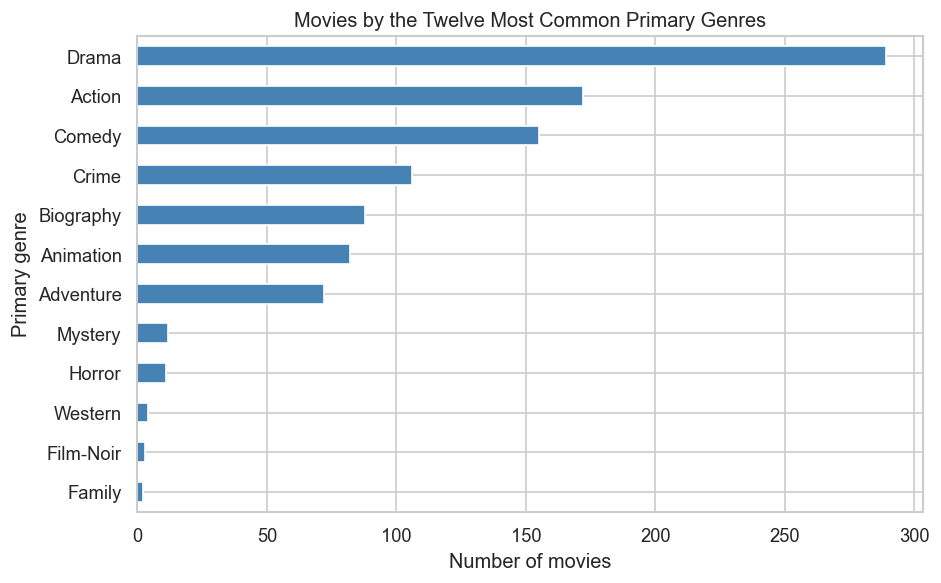

,movie_count,median_rating,median_runtime
primary_genre,,,
Family,2,7.8,107.5
Film-Noir,3,8.0,104.0
Western,4,8.4,148.0
Horror,11,7.8,103.0
Mystery,12,8.0,117.5
Adventure,72,7.9,127.0
Animation,82,7.9,99.5
Biography,88,7.9,129.0
Crime,106,8.0,122.0


In [6]:
top_primary_genres = primary_genre_summary.head(12).sort_values("movie_count")
ax = top_primary_genres["movie_count"].plot(kind="barh", figsize=(8, 5), color="steelblue")
ax.set(title="Movies by the Twelve Most Common Primary Genres", xlabel="Number of movies", ylabel="Primary genre")
plt.tight_layout()
plt.show()
display(top_primary_genres[["movie_count", "median_rating", "median_runtime"]].round(2))

## 8. Pivot table and crosstab

The pivot table counts movies by primary genre and release decade. The crosstab counts movie records by primary genre and certificate. These tables make categorical comparisons easier to inspect.

Because one release year is not parseable, that movie has no decade and is omitted from the decade pivot. Missing certificates are retained as a category in the crosstab. The counts describe this selected list only.

In [7]:
decade_pivot = pd.pivot_table(
    movies.dropna(subset=["release_decade"]), index="primary_genre", columns="release_decade",
    values="Series_Title", aggfunc="nunique", fill_value=0
)
certificate_crosstab = pd.crosstab(movies["primary_genre"], movies["Certificate"], dropna=False)
certificate_share = pd.crosstab(movies["primary_genre"], movies["Certificate"], normalize="index", dropna=False)
display(decade_pivot.head(10))
display(certificate_crosstab.head(10))
display(certificate_share.head(8).round(2))

release_decade,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
primary_genre,,,,,,,,,,,
Action,2,2,3,2,11,11,19,16,51,55,0
Adventure,1,3,2,8,5,8,8,3,18,15,0
Animation,0,0,1,0,1,3,8,18,22,28,1
Biography,1,0,0,0,6,8,8,14,22,28,1
Comedy,2,9,8,8,10,13,19,27,27,30,2
Crime,0,2,4,13,6,5,6,26,27,17,0
Drama,3,6,14,23,27,22,18,43,67,64,2
Family,0,0,0,0,0,1,1,0,0,0,0
Fantasy,2,0,0,0,0,0,0,0,0,0,0


Certificate,16,A,Approved,G,GP,PG,PG-13,Passed,R,TV-14,TV-MA,TV-PG,U,U/A,UA,Unrated,nan
primary_genre,,,,,,,,,,,,,,,,,
Action,0,41,1,1,0,3,6,4,16,0,0,0,20,0,66,0,14
Adventure,0,8,0,0,1,7,1,5,8,0,0,0,28,0,12,0,2
Animation,1,3,0,2,0,7,3,0,1,0,0,0,57,0,6,0,2
Biography,0,17,0,2,0,4,8,2,16,0,0,0,24,0,14,0,1
Comedy,0,18,2,5,0,6,7,10,29,0,0,1,37,0,21,1,18
Crime,0,43,1,0,1,0,1,3,21,0,1,0,8,0,12,0,16
Drama,0,55,6,2,0,8,16,10,53,1,0,1,55,1,41,0,40
Family,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0
Fantasy,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2


Certificate,16,A,Approved,G,GP,PG,PG-13,Passed,R,TV-14,TV-MA,TV-PG,U,U/A,UA,Unrated,nan
primary_genre,,,,,,,,,,,,,,,,,
Action,0.00,0.24,0.01,0.01,0.00,0.02,0.03,0.02,0.09,0.0,0.00,0.00,0.12,0.0,0.38,0.00,0.08
Adventure,0.00,0.11,0.00,0.00,0.01,0.10,0.01,0.07,0.11,0.0,0.00,0.00,0.39,0.0,0.17,0.00,0.03
Animation,0.01,0.04,0.00,0.02,0.00,0.09,0.04,0.00,0.01,0.0,0.00,0.00,0.70,0.0,0.07,0.00,0.02
Biography,0.00,0.19,0.00,0.02,0.00,0.05,0.09,0.02,0.18,0.0,0.00,0.00,0.27,0.0,0.16,0.00,0.01
Comedy,0.00,0.12,0.01,0.03,0.00,0.04,0.05,0.06,0.19,0.0,0.00,0.01,0.24,0.0,0.14,0.01,0.12
Crime,0.00,0.40,0.01,0.00,0.01,0.00,0.01,0.03,0.20,0.0,0.01,0.00,0.07,0.0,0.11,0.00,0.15
Drama,0.00,0.19,0.02,0.01,0.00,0.03,0.06,0.03,0.18,0.0,0.00,0.00,0.19,0.0,0.14,0.00,0.14
Family,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,1.00,0.0,0.00,0.00,0.00


The pivot table cells count distinct movie titles for each primary-genre and decade combination. The crosstab shows certificate counts by primary genre, while the normalized table reports the within-genre proportions. These are descriptive counts, not population shares.

## 9. Data reshaping

The genre summary is reshaped with `melt()` and `pivot()`. `melt()` converts movie count and median rating into measure/value rows; `pivot()` returns them to separate columns. `stack()` and `unstack()` move decade values between columns and the row index in the genre-by-decade table.

Reshaping changes the layout of a summary, not its meaning. Long format can be useful for plotting several measures together, while wide format is convenient for comparing a small number of measures side by side.

In [8]:
wide_genre = primary_genre_summary.head(6).reset_index()[["primary_genre", "movie_count", "median_rating"]]
long_genre = wide_genre.melt(id_vars="primary_genre", var_name="measure", value_name="value")
wide_again = long_genre.pivot(index="primary_genre", columns="measure", values="value")
small_decade = decade_pivot.head(6)
stacked_decade = small_decade.stack()
unstacked_decade = stacked_decade.unstack(fill_value=0)
display(long_genre)
display(wide_again)
display(unstacked_decade)

,primary_genre,measure,value
0,Drama,movie_count,289.0
1,Action,movie_count,172.0
2,Comedy,movie_count,155.0
3,Crime,movie_count,106.0
4,Biography,movie_count,88.0
5,Animation,movie_count,82.0
6,Drama,median_rating,8.0
7,Action,median_rating,7.9
8,Comedy,median_rating,7.9
9,Crime,median_rating,8.0


measure,median_rating,movie_count
primary_genre,,
Action,7.9,172.0
Animation,7.9,82.0
Biography,7.9,88.0
Comedy,7.9,155.0
Crime,8.0,106.0
Drama,8.0,289.0


release_decade,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
primary_genre,,,,,,,,,,,
Action,2,2,3,2,11,11,19,16,51,55,0
Adventure,1,3,2,8,5,8,8,3,18,15,0
Animation,0,0,1,0,1,3,8,18,22,28,1
Biography,1,0,0,0,6,8,8,14,22,28,1
Comedy,2,9,8,8,10,13,19,27,27,30,2
Crime,0,2,4,13,6,5,6,26,27,17,0


The long and wide outputs contain the same summary values in different layouts. The stacked and unstacked results show the same genre-by-decade counts, with decade values moved between the index and columns.

## 10. Data integration and join checks

Only one raw table was supplied, so a true integration between two related source tables is not possible here. This section uses a primary-genre summary derived from the movie table to demonstrate join methods. It is clearly labelled as a derived summary, not a second source table.

The summary has one row per primary genre. Each movie should match one summary row, so the expected relationship is many movies to one genre summary. `validate="many_to_one"` checks the key expectation, merge indicators count matched rows, and the row count before and after is compared.

The section also demonstrates right and outer joins, an index-based join, and concatenation on selected portions of the movie table. A full related-table integration would need another source file and its key definitions.

In [9]:
genre_lookup = primary_genre_summary.reset_index()[["primary_genre", "movie_count", "median_rating"]]
print("Movie rows before merge:", len(movies))
print("Genre summary key unique:", genre_lookup["primary_genre"].is_unique)
movie_genre_left = movies.merge(genre_lookup, on="primary_genre", how="left", validate="many_to_one", indicator=True, suffixes=("", "_summary"))
movie_genre_right = movies[["Series_Title", "primary_genre"]].merge(genre_lookup, on="primary_genre", how="right", validate="many_to_one", indicator=True)
movie_genre_outer = movies[["Series_Title", "primary_genre"]].merge(genre_lookup, on="primary_genre", how="outer", validate="many_to_one", indicator=True)
print("Left, right, outer rows:", len(movie_genre_left), len(movie_genre_right), len(movie_genre_outer))
display(movie_genre_left["_merge"].value_counts())
display(movie_genre_outer["_merge"].value_counts())

index_join = movies.set_index("Series_Title").join(movies[["Series_Title", "IMDB_Rating"]].set_index("Series_Title").add_suffix("_check"), how="left")
concat_example = pd.concat([movies.head(5), movies.tail(5)], ignore_index=True)
print("Index join row count:", len(index_join))
print("Selected-row concat count:", len(concat_example))

Movie rows before merge: 1000
Genre summary key unique: True
Left, right, outer rows: 1000 1000 1000
Index join row count: 1002
Selected-row concat count: 10


_merge
both          1000
left_only        0
right_only       0
Name: count, dtype: int64

_merge
both          1000
left_only        0
right_only       0
Name: count, dtype: int64

The left merge should preserve all movie rows because the genre summary key is unique and each movie has one primary genre. The join indicator confirms whether all movie rows found a summary. The right and outer join examples show how join direction changes key retention.

The index join and concatenation demonstrate Pandas operations using this same file. They do not replace integration with a related source table. Any real integration should check keys, row grain, unmatched rows, and row counts before and after joining.

## 11. Descriptive statistics

The notebook calculates mean, median, mode, variance, standard deviation, range, selected percentiles, quartiles, skewness, and excess kurtosis for rating, runtime, votes, gross, and Metascore where values are present.

Vote counts and gross values are often strongly skewed, so means can be affected by a few very large values. Medians and percentiles are included to describe the middle of the data. Gross is converted from text but its currency and reporting basis are not further verified in the supplied file.

In [10]:
stat_columns = ["IMDB_Rating", "runtime_minutes", "No_of_Votes", "gross_amount", "Meta_score"]
stats = movies[stat_columns].agg(["count", "mean", "median", "std", "var", "min", "max"]).T
stats["mode"] = movies[stat_columns].mode().iloc[0]
stats["range"] = stats["max"] - stats["min"]
stats["skewness"] = movies[stat_columns].skew()
stats["kurtosis_excess"] = movies[stat_columns].kurt()
display(stats.round(3))

percentiles = movies[["IMDB_Rating", "runtime_minutes", "No_of_Votes", "gross_amount"]].quantile([.10, .25, .50, .75, .90]).T
percentiles.columns = ["10%", "Q1", "median", "Q3", "90%"]
display(percentiles.round(2))
five_number = movies[["IMDB_Rating", "runtime_minutes", "No_of_Votes"]].quantile([0, .25, .5, .75, 1]).T
five_number.columns = ["minimum", "Q1", "median", "Q3", "maximum"]
display(five_number.round(2))

,count,mean,median,std,var,min,max,mode,range,skewness,kurtosis_excess
IMDB_Rating,1000.0,7.949000e+00,7.9,2.750000e-01,7.600000e-02,7.6,9.3,7.7,1.7,1.017,1.433
runtime_minutes,1000.0,1.228910e+02,119.0,2.809400e+01,7.892540e+02,45.0,321.0,100.0,276.0,1.208,3.426
No_of_Votes,1000.0,2.736929e+05,138548.5,3.273727e+05,1.071729e+11,25088.0,2343110.0,65341.0,2318022.0,2.3,6.895
gross_amount,831.0,6.803475e+07,23530892.0,1.097500e+08,1.204507e+16,1305.0,936662225.0,4360000.0,936660920.0,3.13,13.914
Meta_score,843.0,7.797200e+01,79.0,1.237600e+01,1.531680e+02,28.0,100.0,76.0,72.0,-0.605,0.421


,10%,Q1,median,Q3,90%
IMDB_Rating,7.6,7.7,7.9,8.1,8.3
runtime_minutes,93.0,103.0,119.0,137.0,159.1
No_of_Votes,34065.7,55526.25,138548.5,374161.25,699297.7
gross_amount,495770.0,3253559.0,23530892.0,80750893.5,206852432.0


,minimum,Q1,median,Q3,maximum
IMDB_Rating,7.6,7.7,7.9,8.1,9.3
runtime_minutes,45.0,103.0,119.0,137.0,321.0
No_of_Votes,25088.0,55526.25,138548.5,374161.25,2343110.0


The mean uses all observed values and can move due to extremes; the median is the central observation after sorting. Q1 and Q3 mark the 25th and 75th percentiles, and the IQR (Q3 - Q1) covers the middle half. Variance is in squared units, while standard deviation and range use the original units.

Missing gross and Metascore values reduce the number of observations used for those statistics. Their count values in the output should be checked before comparing measures.

## 12. Distribution analysis

Histograms show IMDb ratings, runtime, and vote counts. Vote counts are plotted on a logarithmic scale because they span a wide range. A runtime box plot shows spread and possible extremes.

The observed data is described from its plots and statistics rather than being forced to match a distribution. The controlled examples are simulated and clearly labelled to show normal, positively skewed, negatively skewed, and bimodal shapes if the selected movie fields do not provide clear cases.

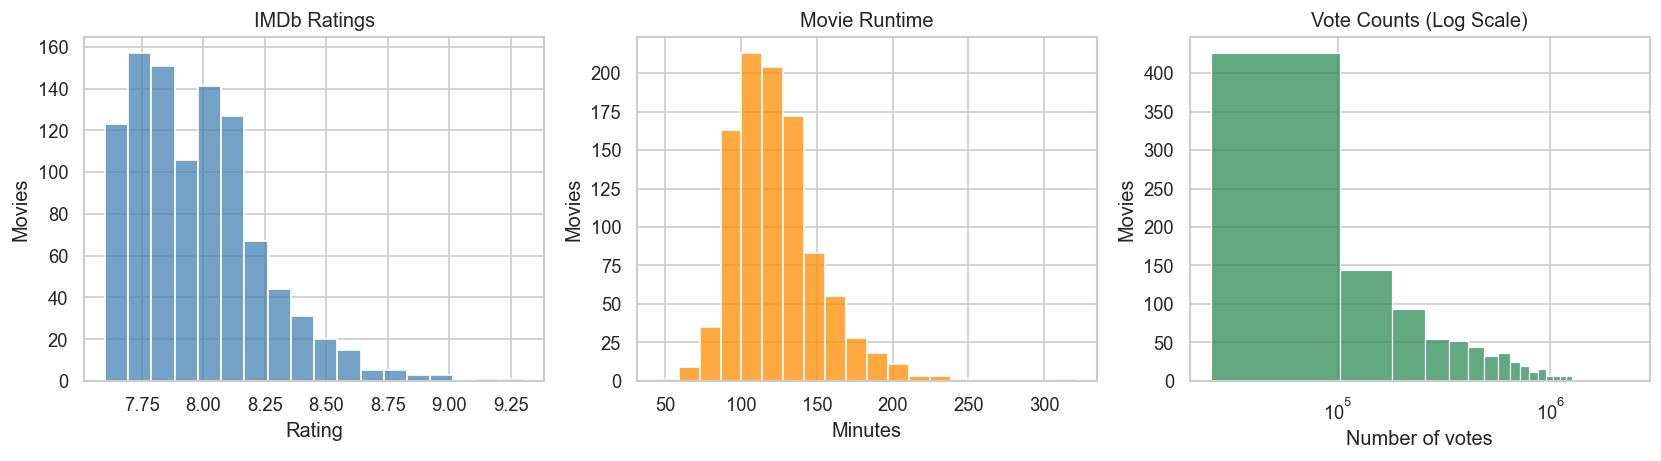

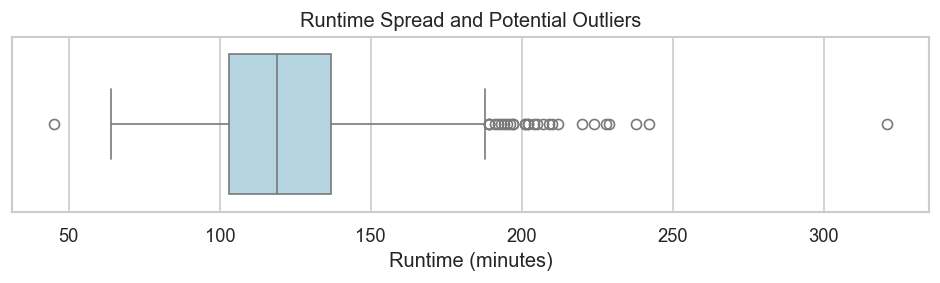

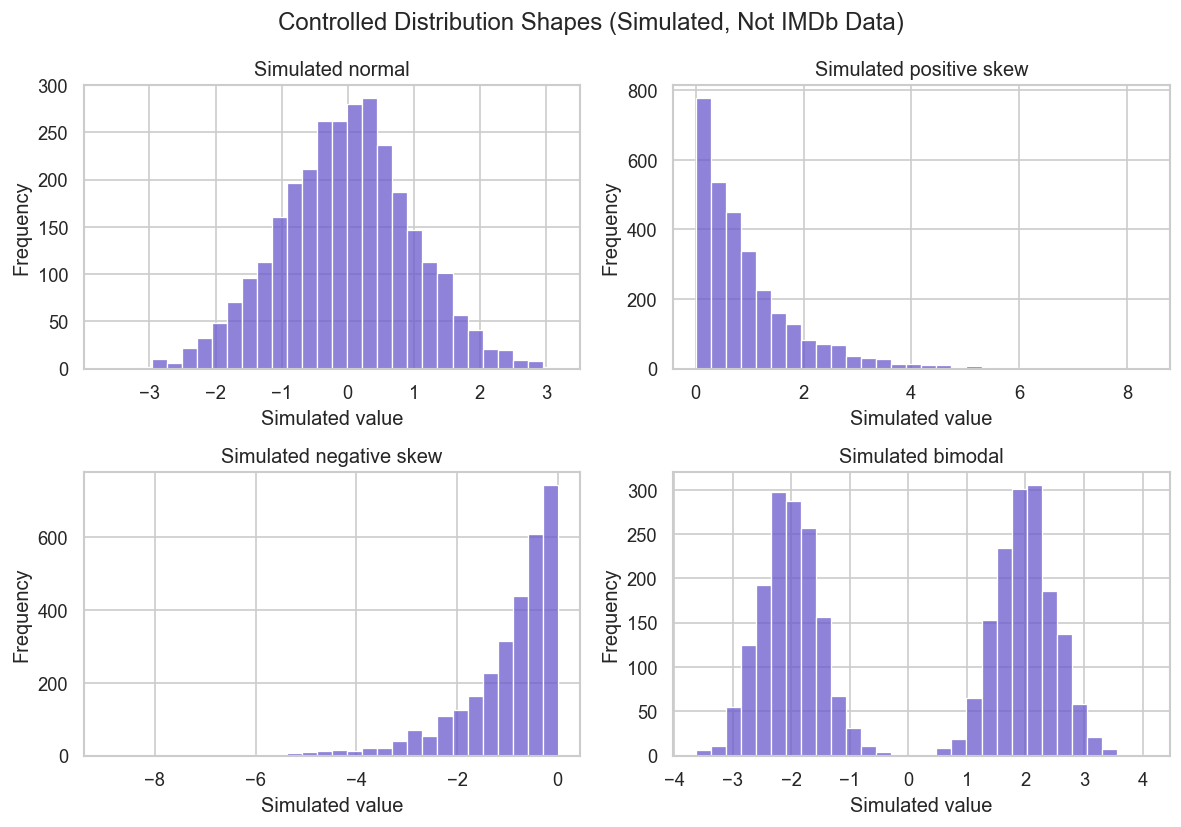

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(movies["IMDB_Rating"], bins=18, ax=axes[0], color="steelblue")
axes[0].set(title="IMDb Ratings", xlabel="Rating", ylabel="Movies")
sns.histplot(movies["runtime_minutes"], bins=20, ax=axes[1], color="darkorange")
axes[1].set(title="Movie Runtime", xlabel="Minutes", ylabel="Movies")
sns.histplot(movies["No_of_Votes"], bins=30, ax=axes[2], color="seagreen")
axes[2].set_xscale("log")
axes[2].set(title="Vote Counts (Log Scale)", xlabel="Number of votes", ylabel="Movies")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=movies["runtime_minutes"], color="lightblue")
plt.title("Runtime Spread and Potential Outliers")
plt.xlabel("Runtime (minutes)")
plt.tight_layout()
plt.show()

shape_rng = np.random.default_rng(RANDOM_SEED)
shape_examples = {
    "Simulated normal": shape_rng.normal(size=3000),
    "Simulated positive skew": shape_rng.exponential(size=3000),
    "Simulated negative skew": -shape_rng.exponential(size=3000),
    "Simulated bimodal": np.r_[shape_rng.normal(-2, .5, 1500), shape_rng.normal(2, .5, 1500)],
}
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (label, values) in zip(axes.flat, shape_examples.items()):
    sns.histplot(values, bins=30, ax=ax, color="slateblue")
    ax.set(title=label, xlabel="Simulated value", ylabel="Frequency")
fig.suptitle("Controlled Distribution Shapes (Simulated, Not IMDb Data)")
plt.tight_layout()
plt.show()

**Rating histogram observations:** The ratings occupy a narrow part of the 0-to-10 scale because the file contains selected top-rated movies. This is a property of the selected list and should not be generalized to all films.

**Runtime and votes observations:** Runtime values are more directly interpretable in minutes, while vote counts vary widely and need a log scale to show smaller and larger values together. High vote counts may reflect well-known films rather than errors.

**Box-plot observation:** Points beyond the runtime whiskers are potential outliers, but unusually short or long movies can be valid films.

**Simulated shape observations:** The positive and negative skew examples have tails in opposite directions; the bimodal example has two peaks. These are simulated shapes and are not movie records.

## 13. Empirical rule demonstration

The movie fields do not provide a clear, approximately normal measurement for this exercise: ratings are concentrated by the top-1000 selection and votes and gross are skewed. A controlled normal simulation is therefore used to demonstrate the empirical rule.

The rule expects about 68% of observations within one standard deviation of the mean, 95% within two, and 99.7% within three for an approximately bell-shaped distribution. The code calculates the actual percentages for a fixed-seed simulated sample.

,observed_percent
within 1 standard deviation,68.19
within 2 standard deviations,95.54
within 3 standard deviations,99.69


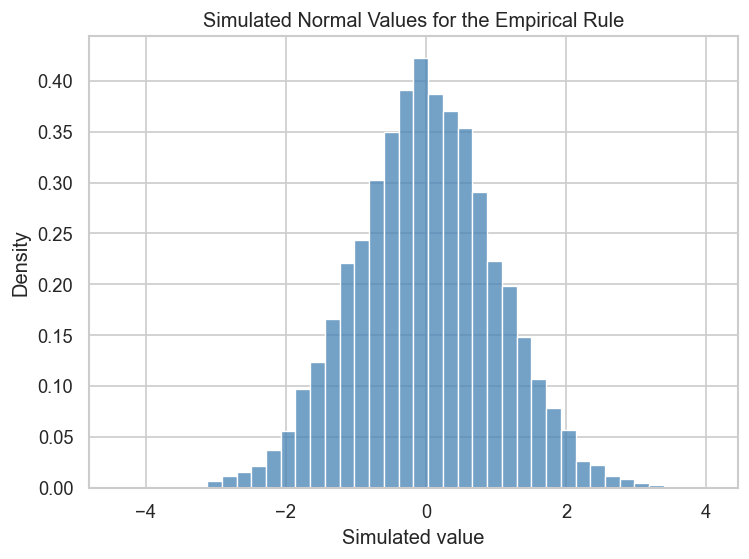

In [12]:
normal_demo = np.random.default_rng(RANDOM_SEED).normal(size=10000)
demo_mean, demo_sd = normal_demo.mean(), normal_demo.std(ddof=1)
empirical_rule = pd.Series({
    "within 1 standard deviation": np.mean(np.abs(normal_demo - demo_mean) <= demo_sd) * 100,
    "within 2 standard deviations": np.mean(np.abs(normal_demo - demo_mean) <= 2 * demo_sd) * 100,
    "within 3 standard deviations": np.mean(np.abs(normal_demo - demo_mean) <= 3 * demo_sd) * 100,
}, name="observed_percent")
display(empirical_rule.round(2).to_frame())
sns.histplot(normal_demo, bins=40, stat="density", color="steelblue")
plt.title("Simulated Normal Values for the Empirical Rule")
plt.xlabel("Simulated value")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

The calculated percentages should be close to the 68%, 95%, and 99.7% reference values, with small differences because the simulation is finite. The rule does not apply automatically to skewed or multi-peaked data.

This is a labelled simulation and is not evidence that movie ratings, runtimes, votes, or gross follow a normal distribution.

## 14. Sampling and the Central Limit Theorem

The observed IMDb ratings in this file are used as the source population for repeated sampling. A fixed random seed makes the demonstration reproducible. The code draws 500 samples with replacement at sizes 30 and 100 and plots the distribution of sample means.

The Central Limit Theorem says that, under its conditions, sample means tend to form a more nearly normal distribution as sample size increases. The spread of those means generally decreases as sample size grows. Since this file is a selected top-movies list, the sampling results describe this table and do not estimate ratings for all movies.

,sample size,mean of sample means,standard deviation of sample means
0,30,7.951,0.051
1,100,7.949,0.028


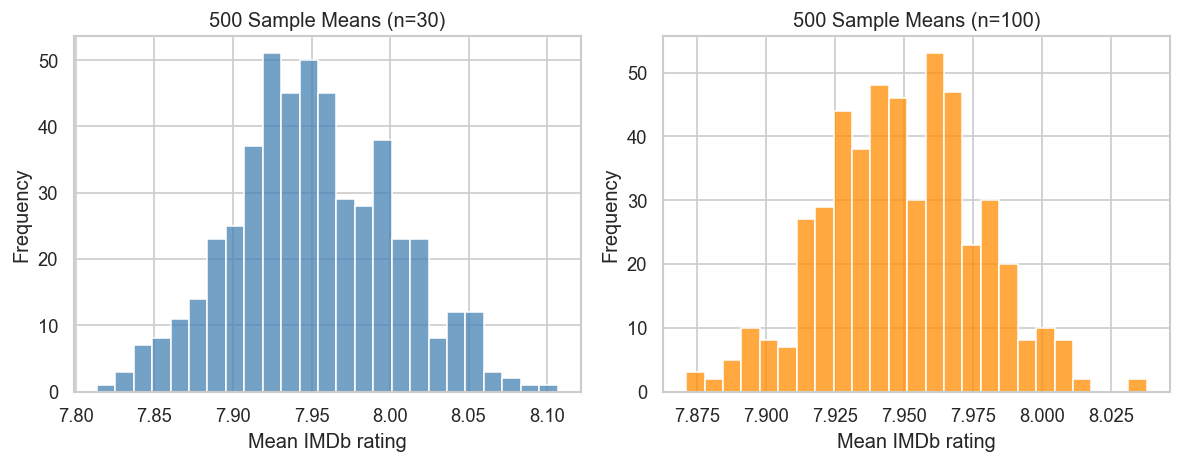

In [13]:
rating_population = movies["IMDB_Rating"].dropna().to_numpy()
rng = np.random.default_rng(RANDOM_SEED)
repetitions = 500
means_30 = np.array([rng.choice(rating_population, size=30, replace=True).mean() for _ in range(repetitions)])
means_100 = np.array([rng.choice(rating_population, size=100, replace=True).mean() for _ in range(repetitions)])
sampling_summary = pd.DataFrame({
    "sample size": [30, 100],
    "mean of sample means": [means_30.mean(), means_100.mean()],
    "standard deviation of sample means": [means_30.std(ddof=1), means_100.std(ddof=1)],
})
display(sampling_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(means_30, bins=25, ax=axes[0], color="steelblue")
axes[0].set(title="500 Sample Means (n=30)", xlabel="Mean IMDb rating", ylabel="Frequency")
sns.histplot(means_100, bins=25, ax=axes[1], color="darkorange")
axes[1].set(title="500 Sample Means (n=100)", xlabel="Mean IMDb rating", ylabel="Frequency")
plt.tight_layout()
plt.show()

**Observations:** Both sets of sample means are centered near the source-table mean rating. The sample means for size 100 have a smaller spread than those for size 30 in this run.

The histograms show sample-to-sample variation. The fixed seed makes the same samples reproducible. The selected top-1000 list limits the interpretation to these movies.

## 15. Correlation and relationship analysis

The correlation analysis compares IMDb rating, Metascore, runtime, log vote count, and log gross. Log transforms reduce the scale difference caused by highly skewed vote and gross amounts. Pairwise calculations use available values, so the number of observations can differ by variable pair.

Pearson correlation measures linear association; Spearman correlation measures monotonic rank association. Covariance depends on each variable's units. A heatmap summarizes Pearson correlations, and a scatter plot shows IMDb rating against Metascore. These relationships are observational and do not establish causation.

Covariance matrix:
Pearson correlation:
Spearman correlation:


,IMDB_Rating,Meta_score,runtime_minutes,log_vote_count,log_gross
IMDB_Rating,0.076,0.943,1.881,0.044,-0.001
Meta_score,0.943,153.168,-10.526,-0.351,-0.563
runtime_minutes,1.881,-10.526,789.254,1.897,4.078
log_vote_count,0.044,-0.351,1.897,0.237,0.323
log_gross,-0.001,-0.563,4.078,0.323,1.096


,IMDB_Rating,Meta_score,runtime_minutes,log_vote_count,log_gross
IMDB_Rating,1.000,0.269,0.243,0.325,-0.004
Meta_score,0.269,1.000,-0.031,-0.060,-0.046
runtime_minutes,0.243,-0.031,1.000,0.139,0.142
log_vote_count,0.325,-0.060,0.139,1.000,0.649
log_gross,-0.004,-0.046,0.142,0.649,1.000


,IMDB_Rating,Meta_score,runtime_minutes,log_vote_count,log_gross
IMDB_Rating,1.000,0.285,0.212,0.214,-0.050
Meta_score,0.285,1.000,-0.089,-0.072,-0.100
runtime_minutes,0.212,-0.089,1.000,0.159,0.178
log_vote_count,0.214,-0.072,0.159,1.000,0.699
log_gross,-0.050,-0.100,0.178,0.699,1.000


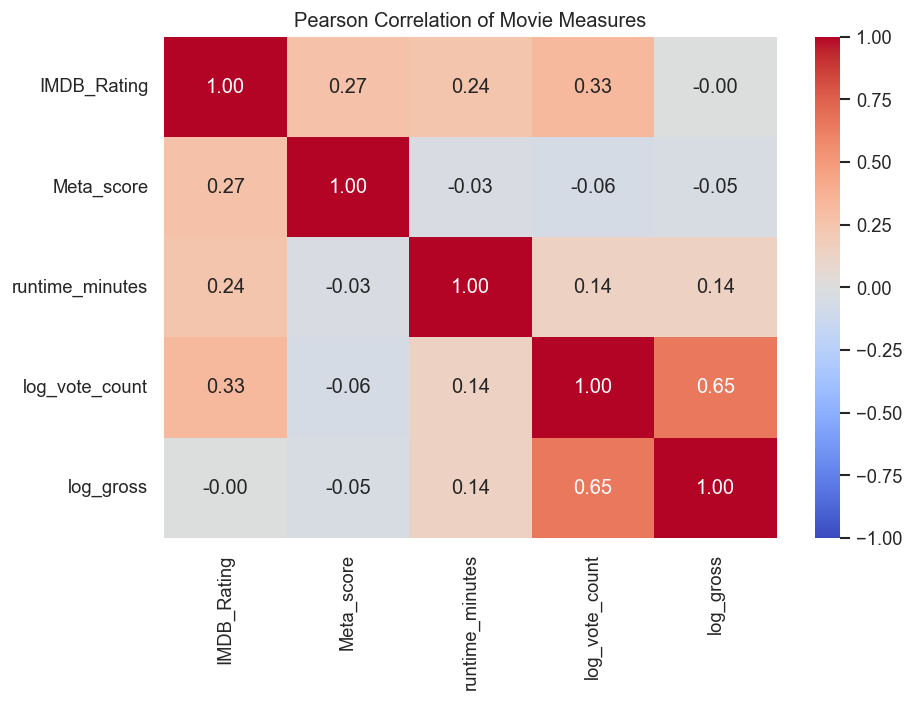

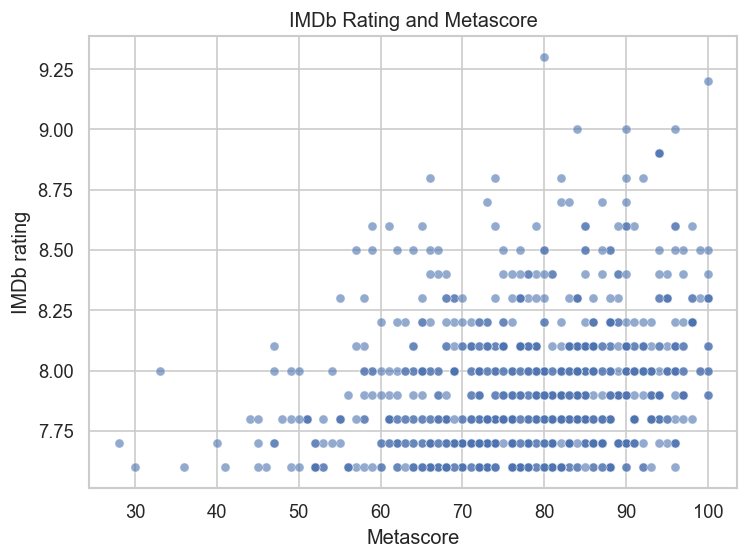

In [14]:
correlation_columns = ["IMDB_Rating", "Meta_score", "runtime_minutes", "log_vote_count", "log_gross"]
correlation_data = movies[correlation_columns]
print("Covariance matrix:")
display(correlation_data.cov().round(3))
pearson = correlation_data.corr(method="pearson")
spearman = correlation_data.corr(method="spearman")
print("Pearson correlation:")
display(pearson.round(3))
print("Spearman correlation:")
display(spearman.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(pearson, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Pearson Correlation of Movie Measures")
plt.tight_layout()
plt.show()

scatter_data = movies[["IMDB_Rating", "Meta_score"]].dropna()
sns.scatterplot(data=scatter_data, x="Meta_score", y="IMDB_Rating", alpha=.6, s=30)
plt.title("IMDb Rating and Metascore")
plt.xlabel("Metascore")
plt.ylabel("IMDb rating")
plt.tight_layout()
plt.show()

The heatmap displays the pairwise Pearson coefficients for the selected fields. Missing Meta_score and gross values mean some pairs use fewer movies than others. The scatter plot shows how IMDb ratings vary across Metascore values.

Pearson and Spearman values can differ if a relationship is nonlinear or influenced by ranks and extreme observations. Neither coefficient proves one score causes another; both are descriptive associations in this selected dataset.

## 16. Outlier detection and treatment

Vote counts are strongly skewed, so outlier detection is applied to `log_vote_count`. The IQR method flags values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. The Z-score method flags absolute standardized scores greater than 3.

The output reports each method's count and percentage. Separate comparisons show summary statistics after IQR-based removal and capping. The original vote counts are not changed. A very high vote count can be meaningful for a popular film, so statistical flags are treated as review points rather than errors.

In [15]:
vote_values = movies["log_vote_count"].dropna()
q1, q3 = vote_values.quantile([.25, .75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_mask = (vote_values < lower_fence) | (vote_values > upper_fence)
z_scores = (vote_values - vote_values.mean()) / vote_values.std(ddof=0)
z_mask = z_scores.abs() > 3
outlier_summary = pd.DataFrame({
    "method": ["IQR fences on log votes", "absolute Z-score > 3 on log votes"],
    "count": [int(iqr_mask.sum()), int(z_mask.sum())],
})
outlier_summary["percent"] = outlier_summary["count"] / len(vote_values) * 100
display(outlier_summary.round(2))

retained = vote_values.loc[~iqr_mask]
capped = vote_values.clip(lower=lower_fence, upper=upper_fence)
treatment = pd.DataFrame({
    "original": [vote_values.mean(), vote_values.median(), vote_values.std(), vote_values.max()],
    "IQR flagged removed": [retained.mean(), retained.median(), retained.std(), retained.max()],
    "IQR capped": [capped.mean(), capped.median(), capped.std(), capped.max()],
}, index=["mean log votes", "median log votes", "standard deviation", "maximum log votes"])
display(treatment.round(3))

,method,count,percent
0,IQR fences on log votes,0,0.0
1,absolute Z-score > 3 on log votes,0,0.0


,original,IQR flagged removed,IQR capped
mean log votes,5.171,5.171,5.171
median log votes,5.142,5.142,5.142
standard deviation,0.487,0.487,0.487
maximum log votes,6.370,6.370,6.370


Outlier rules identify values that are unusual compared with the rest of the selected list; they do not establish that the data is incorrect. Films with many votes may be important examples in a top-movies dataset.

Removal and capping are demonstrated on separate copies of the log-transformed vote values. The raw vote counts remain unchanged. Retaining valid observations is appropriate unless source review or the analysis goal supports another decision.

## 17. Findings, limitations, and future scope

The notebook reports movie ratings, runtimes, genres, release periods, vote counts, gross values, and Metascores from the supplied file. It also checks missing fields and leaves the unparseable *Apollo 13* year as missing rather than guessing a correction.

Important limitations:

- The dataset is a selected top-1000 list and is not a random sample of all films.
- The file is a snapshot; rankings and metadata can change.
- Metascore, certificate, and gross contain missing values.
- The release year for *Apollo 13* is malformed in the supplied file and is excluded from year-based summaries.
- The source does not specify enough context here to verify the currency or reporting basis of `Gross`.
- Genre is multi-valued; exploded genre rows can count one film in more than one genre.
- Correlation does not show causation.
- Only one raw table was supplied, so integration with an independent related table is not possible.

For a broader project, add a related source table only after recording its source and licence, identifying its row grain, and defining a validated key. Compare row counts and unmatched keys after each join.

## 18. Conclusion

This analysis checked the movie table, created parsed and derived fields, summarized ratings and genres, reshaped summary tables, and demonstrated descriptive and statistical methods. The data is useful for describing the selected top-1000 records and comparing the fields included in this snapshot.

The results should not be generalized to every movie or interpreted causally. Missing values, one malformed release year, multi-valued genres, and the selected-list design limit the conclusions. Any future integration should use an additional source table with a clear key and validated row counts.

All tables and plots in this notebook are generated from code. Simulated examples are labelled and are not represented as IMDb observations.